# Session 6 — Instrumental variables

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to lecture AE1.4 (Instrumental Variables I and II). Simulated data
throughout, so every estimator can be judged against a known truth.

1. The IV estimator by hand: Wald, the ratio of reduced form to first stage,
   and 2SLS — why the "two stages" give the same number as one formula.
2. Weak instruments: a Monte Carlo that shrinks the first stage and watches
   2SLS drift toward OLS, the $t$-test over-reject, and the Anderson–Rubin
   confidence set keep its coverage — and what that set looks like when the
   instrument is weak.
3. Many weak instruments: adding irrelevant instruments pulls 2SLS toward OLS.
4. LATE: compliers, always-takers and never-takers; what IV estimates when
   effects are heterogeneous, and what it does not.
5. The judge (leniency) design: a leave-one-out instrument built from the
   judge's other cases, judge-clustered inference, and what happens when
   monotonicity fails.

Readings: Cunningham (2026), Chapter 7; Huntington-Klein (2025), Chapter 19;
Andrews, Stock and Sun (2019); Lee et al. (2022); Frandsen, Lefgren and
Leslie (2023). Full references at the end of the notebook.

Requirements: `numpy`, `pandas`, `statsmodels`, `scipy`, `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings("ignore")

rng = np.random.default_rng(20261130)
pd.set_option("display.precision", 3)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.family": "sans-serif"})

def ols(y, X):
    return sm.OLS(np.asarray(y, float), sm.add_constant(np.asarray(X, float))).fit()

def tsls(y, d, Z, X=None, groups=None):
    # 2SLS with instruments Z (n x k), optional exogenous controls X; returns (beta, se, first-stage F).
    # groups: cluster ids -> cluster-robust SE and cluster-robust first-stage F; otherwise homoskedastic.
    Xc = np.column_stack([np.ones(len(y))] + ([X] if X is not None else []))
    Zf = np.column_stack([Xc, Z])
    k = Xc.shape[1]
    fs = sm.OLS(d, Zf).fit()                                # first stage; F below is the conventional strength diagnostic
    d_hat = fs.fittedvalues
    W = np.column_stack([Xc, d]); What = np.column_stack([Xc, d_hat])
    b = np.linalg.solve(What.T @ W, What.T @ y)
    u = y - W @ b
    A = np.linalg.inv(What.T @ What)
    if groups is None:
        V = (u @ u / (len(y) - W.shape[1])) * A
    else:                                                   # cluster-robust sandwich, small-sample factor G/(G-1)
        g = np.asarray(groups); G = len(np.unique(g))
        meat = sum(np.outer(What[g == c].T @ u[g == c], What[g == c].T @ u[g == c]) for c in np.unique(g))
        V = (G / (G - 1)) * A @ meat @ A
    F = fs.f_test(np.eye(Zf.shape[1])[k:]).fvalue
    return b[-1], np.sqrt(V[-1, -1]), float(F)

## 1. The IV estimator by hand

The structural model with an endogenous regressor: $y = \beta d + u$ with
$\mathrm{Cov}(d,u) \neq 0$, and an instrument $z$ that moves $d$ but is
independent of $u$. In the simulation an unobserved $a$ ("ability") drives both
$d$ and $y$, the true $\beta = 1$, and $z$ is a coin flip that shifts $d$ by
$\pi = 0.5$.

Three ways to the same number:

- **Wald** (binary $z$): $\hat\beta = \dfrac{\bar y_{z=1} - \bar y_{z=0}}{\bar d_{z=1} - \bar d_{z=0}}$;
- **ratio of covariances**: $\hat\beta = \dfrac{\widehat{\mathrm{Cov}}(z,y)}{\widehat{\mathrm{Cov}}(z,d)}$ = reduced form / first stage;
- **2SLS**: regress $d$ on $z$, take $\hat d$, regress $y$ on $\hat d$.

In [2]:
def iv_data(n, pi=0.5, beta=1.0, rho=0.8, rng=rng):
    a = rng.normal(size=n)                      # unobserved confounder
    z = rng.binomial(1, 0.5, n)
    d = pi * z + rho * a + rng.normal(0, np.sqrt(1 - rho**2), n)
    y = beta * d + a + rng.normal(size=n)
    return pd.DataFrame({"y": y, "d": d, "z": z})

df = iv_data(5000)
wald   = (df.y[df.z == 1].mean() - df.y[df.z == 0].mean()) / (df.d[df.z == 1].mean() - df.d[df.z == 0].mean())
rf, fs = ols(df.y, df.z).params[1], ols(df.d, df.z).params[1]
ratio  = np.cov(df.z, df.y)[0, 1] / np.cov(df.z, df.d)[0, 1]
d_hat  = ols(df.d, df.z).fittedvalues
stage2 = ols(df.y, d_hat).params[1]
b2sls, se2sls, F = tsls(df.y.values, df.d.values, df.z.values[:, None])

pd.DataFrame({"estimate": [ols(df.y, df.d).params[1], wald, rf / fs, ratio, stage2, b2sls], "truth": 1.0},
             index=["OLS (biased)", "Wald", "reduced form / first stage", "Cov(z,y)/Cov(z,d)", "2SLS by two regressions", "2SLS (one formula)"])

,estimate,truth
OLS (biased),1.787,1.000
Wald,0.920,1.000
reduced form / first stage,0.920,1.000
"Cov(z,y)/Cov(z,d)",0.920,1.000
2SLS by two regressions,0.920,1.000
2SLS (one formula),0.920,1.000


OLS is biased upward (ability raises both schooling and earnings); the five IV
computations agree to the last digit because they are the same estimator.
One caution the lecture stresses: the standard error from the "second
regression" is wrong — it uses residuals from $\hat d$ rather than $d$. Always
use an IV routine (or the one-formula version above) for inference.

## 2. Weak instruments

Now shrink the first stage. For each $\pi$ we draw 500 samples of $n = 1{,}000$
and record the 2SLS estimate, its $t$-test rejection rate of the true
$\beta = 1$ (should be 5 %), the first-stage $F$, and the coverage of the
**Anderson–Rubin** 95 % confidence set. The AR set inverts a test: for every
candidate $\beta_0$ it regresses $y - \beta_0 d$ on $z$ and keeps $\beta_0$ if
the coefficient on $z$ is insignificant. No first stage is needed, which is
why the test keeps its size when the first stage is weak — and why the set
need not be an interval: it can be bounded, unbounded on one or both sides,
or two disjoint rays. We construct it on a wide grid below.

In [3]:
def ar_covers(y, d, z, beta0=1.0, alpha=0.05):
    f = ols(y - beta0 * d, z)
    return f.pvalues[1] > alpha

def weak_study(pi, n=1000, reps=500, rng=rng):
    b_ols, b_iv, rej_t, Fs, ar_cov, ci_cov = [], [], [], [], [], []
    for _ in range(reps):
        df = iv_data(n, pi=pi, rng=rng)
        y, d, z = df.y.values, df.d.values, df.z.values
        b_ols.append(ols(y, d).params[1])
        b, se, F = tsls(y, d, z[:, None])
        b_iv.append(b); Fs.append(F)
        rej_t.append(abs((b - 1.0) / se) > 1.96)
        ci_cov.append(abs(b - 1.0) <= 1.96 * se)
        ar_cov.append(ar_covers(y, d, z))
    return pd.Series({"pi": pi, "median F": np.median(Fs), "mean OLS": np.mean(b_ols), "median 2SLS": np.median(b_iv),
                      "2SLS 95% CI coverage": np.mean(ci_cov), "AR 95% coverage": np.mean(ar_cov)})

weak = pd.DataFrame([weak_study(pi) for pi in [0.5, 0.25, 0.12, 0.06, 0.03]]).set_index("pi")
weak

,median F,mean OLS,median 2SLS,2SLS 95% CI coverage,AR 95% coverage
pi,,,,,
0.500,62.327,1.754,0.998,0.952,0.940
0.250,14.959,1.792,0.996,0.954,0.956
0.120,3.535,1.797,1.007,0.950,0.954
0.060,0.871,1.800,1.293,0.964,0.946
0.030,0.573,1.800,1.615,0.974,0.948


Read down the table: as the first stage weakens (median $F$ falling from
about 60 to below 1), the median 2SLS estimate drifts from 1 toward the OLS
value (1.8) — the finite-sample bias toward OLS from the lecture. The
$t$-based 2SLS interval happens to keep its coverage in this DGP because its
standard error balloons along with the bias; Lee et al. (2022) show that for
other degrees of endogeneity it can fall well below 95 % at first-stage $F$
in the tens. Their $F > 104.7$ is the worst case over the degree of
endogeneity at which the usual 1.96 test has correct 5 % size in the
single-instrument homoskedastic setting — a guarantee, not a validity line;
the paper's actual proposal is a continuous $tF$ adjustment of the critical
value. The Anderson–Rubin set keeps 95 % coverage at every $F$ under its
assumptions (the 0.94–0.96 in the table is Monte Carlo noise over 500
replications); what changes is its shape. Below we construct the set for one
strong and one weak sample: the strong one is a short interval, the weak one
never rejects anywhere on a grid from $-30$ to $30$ — the whole real line,
which is the honest answer when the data cannot pin $\beta$ down at all.
(Between those extremes, AR sets can be one-sided rays or two disjoint
rays.) That is the 2026 advice from
the lecture: judge strength by the (effective) $F$ with a high bar, and
report AR sets in the just-identified case regardless of $F$.

pi = 0.5   F =  65.7   AR 95% set: [0.88, 1.50]   (grid [-30, 30]; -inf/+inf = runs off the grid)


pi = 0.06  F =   1.1   AR 95% set: [-inf, +inf]   (grid [-30, 30]; -inf/+inf = runs off the grid)


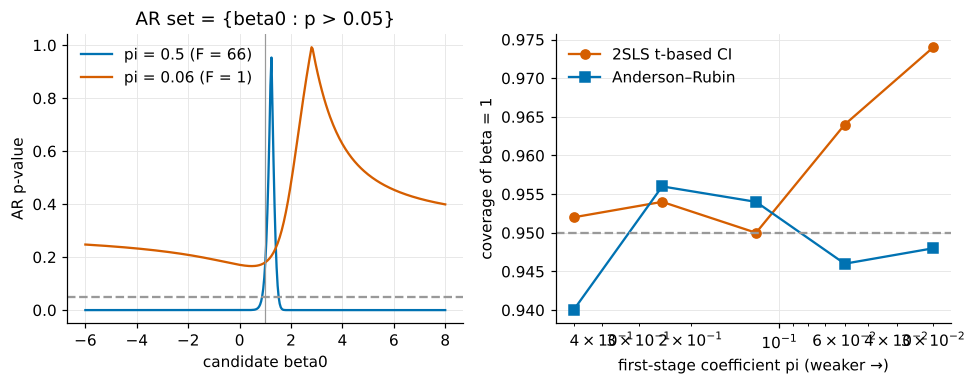

In [4]:
def ar_set(y, d, z, alpha=0.05, lo=-30, hi=30, step=0.02):
    # Anderson-Rubin confidence set by test inversion on a grid; returns the accepted sub-intervals
    grid = np.arange(lo, hi + step, step)
    acc = np.array([ols(y - b0 * d, z).pvalues[1] > alpha for b0 in grid])
    pieces, start = [], None
    for g, a in zip(grid, acc):
        if a and start is None: start = g
        if not a and start is not None: pieces.append((start, g - step)); start = None
    if start is not None: pieces.append((start, grid[-1]))
    def fmt(a, b):
        left = "-inf" if a <= lo + step / 2 else f"{a:.2f}"; right = "+inf" if b >= hi - step / 2 else f"{b:.2f}"
        return f"[{left}, {right}]"
    return " U ".join(fmt(a, b) for a, b in pieces) if pieces else "empty"

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for pi, c in zip([0.5, 0.06], [BLUE, VERMILLION]):
    df = iv_data(1000, pi=pi, rng=np.random.default_rng(7))
    F = tsls(df.y.values, df.d.values, df.z.values[:, None])[2]
    print(f"pi = {pi:<5} F = {F:5.1f}   AR 95% set: {ar_set(df.y.values, df.d.values, df.z.values)}   (grid [-30, 30]; -inf/+inf = runs off the grid)")
    grid = np.linspace(-6, 8, 351)
    pv = [ols(df.y - b0 * df.d, df.z).pvalues[1] for b0 in grid]
    ax[0].plot(grid, pv, color=c, label=f"pi = {pi} (F = {F:.0f})")
ax[0].axhline(0.05, color=GREY, ls="--"); ax[0].axvline(1, color=GREY, lw=0.8)
ax[0].set_xlabel("candidate beta0"); ax[0].set_ylabel("AR p-value"); ax[0].set_title("AR set = {beta0 : p > 0.05}"); ax[0].legend(frameon=False)
ax[1].plot(weak.index, weak["2SLS 95% CI coverage"], "o-", color=VERMILLION, label="2SLS t-based CI")
ax[1].plot(weak.index, weak["AR 95% coverage"], "s-", color=BLUE, label="Anderson–Rubin")
ax[1].axhline(0.95, color=GREY, ls="--"); ax[1].set_xscale("log"); ax[1].invert_xaxis()
ax[1].set_xlabel("first-stage coefficient pi (weaker →)"); ax[1].set_ylabel("coverage of beta = 1"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Many weak instruments

Angrist–Krueger used quarter-of-birth dummies; later work added hundreds of
interactions. Here we keep one real instrument ($\pi = 0.25$) and add $K$
instruments that are pure noise. More instruments mean a better in-sample fit
of the first stage — and a 2SLS estimate that moves toward OLS, because
$\hat d$ starts to pick up the endogenous part of $d$ through overfitting.
We also report the median joint first-stage $F$: it falls mechanically as
the numerator degrees of freedom grow, which is why the single-instrument
$F$ thresholds do not carry over to many instruments (the many-instrument
literature uses the concentration parameter, or Montiel Olea–Pflueger's
effective $F$, instead).

In [5]:
def many_weak(K, n=1000, reps=300, rng=rng):
    b, F = [], []
    for _ in range(reps):
        df = iv_data(n, pi=0.25, rng=rng)
        Z = np.column_stack([df.z.values] + [rng.normal(size=n) for _ in range(K)])
        bb, _, FF = tsls(df.y.values, df.d.values, Z)
        b.append(bb); F.append(FF)
    return pd.Series({"median 2SLS (truth 1, OLS ≈ 1.8)": np.median(b), "median joint first-stage F": np.median(F)})

pd.DataFrame({K: many_weak(K) for K in [0, 5, 20, 50, 100]}).T.rename_axis("irrelevant instruments added")

,"median 2SLS (truth 1, OLS ≈ 1.8)",median joint first-stage F
irrelevant instruments added,,
0,0.982,16.018
5,1.205,3.295
20,1.470,1.684
50,1.600,1.301
100,1.691,1.138


## 4. LATE: who is the effect about?

Now treatment is binary and people differ in how they respond to the
instrument (a lottery offer): **always-takers** enrol regardless, **never-takers**
never do, **compliers** enrol only if offered, and (ruled out by monotonicity)
**defiers** would do the opposite. Effects are heterogeneous: compliers gain
$\tau = 2$, always-takers $\tau = 3$ (they select on gains), never-takers would
gain $0.5$. Under the five LATE assumptions, IV identifies the effect for
compliers only.

In [6]:
def late_data(n=20000, defier_share=0.0, rng=rng):
    u = rng.uniform(size=n)
    typ = np.where(u < 0.2, "always", np.where(u < 0.5, "never", np.where(u < 1 - defier_share, "complier", "defier")))
    z = rng.binomial(1, 0.5, n)
    d = np.select([typ == "always", typ == "never", typ == "complier", typ == "defier"], [1, 0, z, 1 - z])
    tau = np.select([typ == "always", typ == "never", typ == "complier", typ == "defier"], [3.0, 0.5, 2.0, 2.0])
    y0 = np.select([typ == "always", typ == "never"], [1.0, -1.0], 0.0) + rng.normal(size=n)   # types differ in Y0 too
    y = y0 + tau * d
    return pd.DataFrame({"y": y, "d": d, "z": z, "typ": typ, "tau": tau})

L = late_data()
first_stage = L.d[L.z == 1].mean() - L.d[L.z == 0].mean()
itt = L.y[L.z == 1].mean() - L.y[L.z == 0].mean()
pd.Series({"first stage (d on z)": first_stage, "realized complier share": (L.typ == "complier").mean(),
           "ITT (reduced form)": itt, "Wald = ITT / first stage": itt / first_stage,
           "true LATE (compliers)": L.tau[L.typ == "complier"].mean(), "true ATE (everyone)": L.tau.mean(),
           "true ATT (treated)": L.tau[L.d == 1].mean(), "naive OLS of y on d": ols(L.y, L.d).params[1]})

first stage (d on z)       0.497
realized complier share    0.495
ITT (reduced form)         1.023
Wald = ITT / first stage   2.057
true LATE (compliers)      2.000
true ATE (everyone)        1.741
true ATT (treated)         2.444
naive OLS of y on d        3.459
dtype: float64

The Wald estimate recovers the complier effect (2), not the ATE (about 1.74)
and not the ATT; the naive comparison of enrolled and non-enrolled is far off because
always-takers have higher $Y^0$ and higher gains. In the population the first stage *is* the
complier share (random assignment, exclusion, monotonicity); in a sample the
two differ by the chance imbalance of types across $z$ arms, here 0.497 vs
0.500. That is why the lecture asks you to report the first stage: it says
whom the LATE is about.

## 5. The judge (leniency) design

Defendants are randomly assigned to one of $J$ judges; judges differ in their
propensity to incarcerate. The instrument for defendant $i$ assigned to judge
$j$ is the judge's **leave-one-out** incarceration rate — the share of the
judge's *other* cases ending in incarceration. Unobserved "criminality" $a$
affects both the decision and the outcome (recidivism), so OLS is biased.
Monotonicity requires that a harsher judge is harsher for everyone. Two
things about inference: defendants of the same judge share (almost) the same
instrument, so the 2SLS standard error is clustered by judge (the first-stage
$F$ is kept as the conventional strength diagnostic); and the instrument is
itself estimated from the other cases, which the clustered SE ignores — with
40 judges and 150 cases each the approximation is acceptable, with few judges
it is not.

In [7]:
def judge_data(n=6000, J=40, violate=False, rng=rng):
    judge = rng.integers(0, J, n)
    harshness = rng.normal(0, 0.8, J)                     # judge-specific propensity to incarcerate
    a = rng.normal(size=n)                                # unobserved criminality
    case_type = rng.binomial(1, 0.5, n)                   # two case types
    if violate:                                           # harsh on type 1 but lenient on type 0: defiers appear
        strictness = np.where(case_type == 1, harshness[judge], -0.6 * harshness[judge])
    else:
        strictness = harshness[judge]
    d = (strictness + 0.8 * a + rng.normal(size=n) > 0).astype(int)      # incarcerated
    tau = np.where(case_type == 1, 1.5, 0.5)                              # heterogeneous effect on recidivism index
    y = tau * d + 1.0 * a + rng.normal(size=n)
    df = pd.DataFrame({"y": y, "d": d, "judge": judge, "a": a, "case": case_type, "tau": tau})
    tot = df.groupby("judge")["d"].transform("sum"); cnt = df.groupby("judge")["d"].transform("count")
    df["z_loo"] = (tot - df["d"]) / (cnt - 1)                              # leave-one-out incarceration rate of the judge
    return df

for violate in [False, True]:
    jd = judge_data(violate=violate)
    b, se, F = tsls(jd.y.values, jd.d.values, jd.z_loo.values[:, None], groups=jd.judge.values)   # clustered by judge
    fs_by_type = [ols(jd.d[jd.case == c], jd.z_loo[jd.case == c]).params[1] for c in (0, 1)]
    print(f"monotonicity {'violated' if violate else 'holds   '}: OLS {ols(jd.y, jd.d).params[1]:.2f} | 2SLS {b:.2f} (judge-clustered SE {se:.2f}, F {F:.0f}) "
          f"| first stage by case type: {fs_by_type[0]:+.2f}, {fs_by_type[1]:+.2f} | true effects 0.5 / 1.5")

monotonicity holds   : OLS 1.83 | 2SLS 1.11 (judge-clustered SE 0.06, F 1666) | first stage by case type: +0.98, +0.98 | true effects 0.5 / 1.5
monotonicity violated: OLS 1.80 | 2SLS 4.69 (judge-clustered SE 2.84, F 4) | first stage by case type: -1.54, +2.07 | true effects 0.5 / 1.5


When monotonicity holds, the leave-one-out leniency instrument gives a LATE
between the two true effects (weighted toward whichever case type has more
marginal defendants) and far from the biased OLS. When judges are harsh on one
case type and lenient on the other, the first stage by case type has opposite
signs, the two cancel in the pooled first stage, which collapses (the
reported $F$ drops from four digits to single digits), and the 2SLS number no
longer corresponds to any average of true effects. Opposite-signed subgroup
first stages are an informal falsification of monotonicity in the spirit of
the Frandsen–Lefgren–Leslie (2023) analysis; their paper develops a formal
joint test of exclusion and monotonicity from the relation between judge
propensities and outcomes, and weaker average-monotonicity conditions under
which IV still has a causal interpretation. Checking first stages across
observable subgroups can reveal a violation; it cannot verify monotonicity.

## Summary

- Wald, covariance ratio and 2SLS are one estimator; use a proper IV routine
  for standard errors.
- Weak first stage: 2SLS drifts toward OLS and the $t$-test lies. Judge strength
  by the effective $F$ with a high bar; report Anderson–Rubin sets, which
  keep their coverage — and can be unbounded when the data cannot pin
  $\beta$ down.
- Adding weak instruments is not free: 2SLS moves toward OLS.
- IV with heterogeneous effects identifies the complier LATE; the first stage is
  the complier share (in the population).
- Judge designs need random assignment, discretion and monotonicity; cluster
  by judge; opposite-signed subgroup first stages falsify monotonicity.

## References

- Andrews, I., Stock, J. H., and Sun, L. (2019). Weak instruments in instrumental variables regression: theory and practice. *Annual Review of Economics*, 11, 727–753. https://doi.org/10.1146/annurev-economics-080218-025643
- Cunningham, S. (2026). *Causal Inference: The Mixtape*, 2nd ed., Chapter 7. https://mixtape.scunning.com
- Frandsen, B., Lefgren, L., and Leslie, E. (2023). Judging judge fixed effects. *American Economic Review*, 113(1), 253–277. https://doi.org/10.1257/aer.20201860
- Huntington-Klein, N. (2025). *The Effect*, 2nd ed., Chapter 19. https://theeffectbook.net
- Lee, D. S., McCrary, J., Moreira, M. J., and Porter, J. (2022). Valid t-ratio inference for IV. *American Economic Review*, 112(10), 3260–3290. https://doi.org/10.1257/aer.20211063
- Montiel Olea, J. L., and Pflueger, C. (2013). A robust test for weak instruments. *Journal of Business & Economic Statistics*, 31(3), 358–369.